# Multivariate Analysis

This notebook aims to show the multivariate analysis used in the paper of Oonk et al. (2023) to see what features differentiated between successful and unsuccessful 1vs1 actions.

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import shapiro, levene, mannwhitneyu
from statsmodels.multivariate.manova import MANOVA


## Load in the data

In [2]:
features = pd.read_pickle("data/features.pickle")
features.loc[features["outcome"]==-1, "outcome"] = 0

X = features.drop("outcome", axis=1).copy()
y = features["outcome"].copy().astype("category")
print("1vs1 action outcome counts:\n", y.value_counts())
# print("\nDescription of features:\n", X.describe())

1vs1 action outcome counts:
 outcome
0.0    378
1.0    356
Name: count, dtype: int64


## Check prerequisits for the multivariate analysis

In this sections the prerequisits for doing a MANOVA are tested:
1. test if the data is normally distributed (note that because of the sample size this is not actually needed (Akritas & Papadatos, 2004), but good to know anyway).
2. Check the homogeneity of variance-covariance matrices using a levene's test.

In [3]:
# check normality of the data. For more information on individual features, un-comment the commented 
# lines in this code block and re-run the code.

successful = X[y==1]
unsuccessful = X[y==0]

normally_distributed = 0
not_normally_distributed = 0

for col in successful.columns:
    # print(col)
    stat, p_value = shapiro(successful[col])
    # print(f"\tP-value for normality of succesful group is {p_value:.4f}")
    if p_value < 0.05:
        not_normally_distributed += 1
    else:
        normally_distributed += 1
    stat, p_value = shapiro(unsuccessful[col])
    # print(f"\tP-value for normality of unsuccessful group is {p_value:.4f}")
    if p_value < 0.05:
        not_normally_distributed += 1
    else:
        normally_distributed += 1
        
print(f"\n{normally_distributed} features are normally distributed, {not_normally_distributed} are not.")



3 features are normally distributed, 45 are not.


In [4]:
# checking levene's test with center=median, since data is not normally distributed
# note that this is equivalant to the Brown-Forsythe test (Brown & Forsythe, 1974).
unequal_variances_cols = []
for col in X.columns:
    stat, p_value = levene(successful[col], unsuccessful[col], center="median")
    if p_value < 0.05:
        unequal_variances_cols.append(col)
        print(f"Levene's test p_value for {col} = {p_value:.3f}")


Levene's test p_value for dist_ball_sideline_start_posession = 0.043
Levene's test p_value for dist_ball_sideline_start_duel = 0.047
Levene's test p_value for min_relative_distance_att_def = 0.027


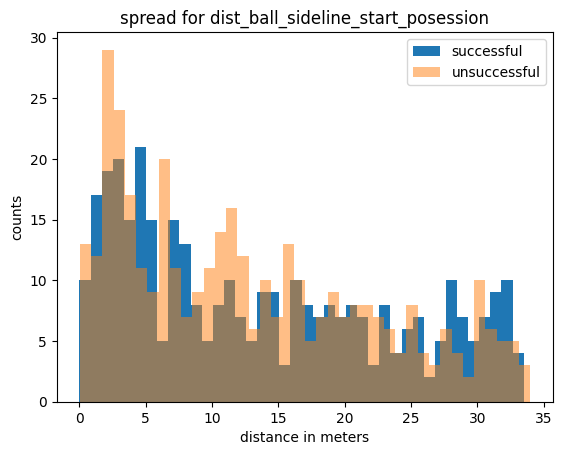

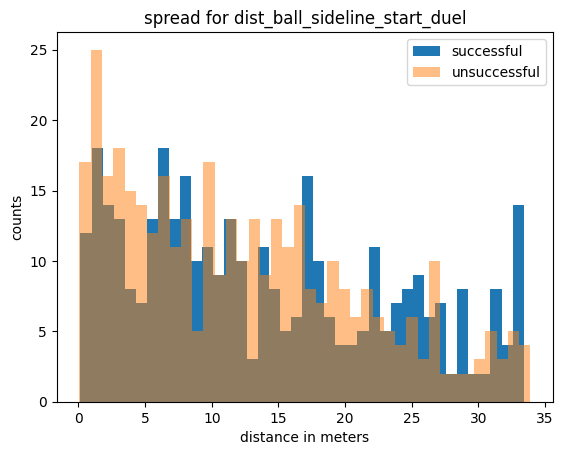

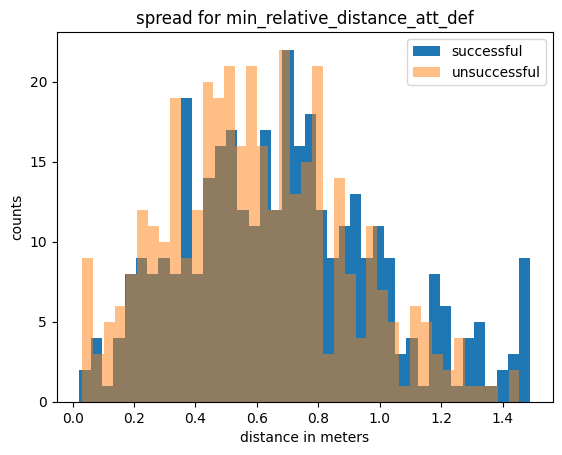

In [5]:
import matplotlib.pyplot as plt

for col in unequal_variances_cols:
    plt.hist(successful[col], bins=40, label="successful")
    plt.hist(unsuccessful[col], bins=40, alpha=.5, label="unsuccessful")
    plt.ylabel("counts")
    plt.xlabel("distance in meters")
    plt.title(f"spread for {col}")
    plt.legend()
    plt.show()

Although not all variances are shown to be equal, we still decided to continue with the MANOVA for the following reasons:
1. Only 3 of the 24 features do not show equal variances.
2. Those three features visually look like they have about the same spread between successful and unsuccessful 1-vs-1 actions.
3. MANOVA's are known to be robust against violations of the assumption that the variances are equal.

## Performing the MANOVA



In [6]:
full_data = pd.concat([X, y], axis=1)
model_formula_string = " + ".join(X.columns) + " ~ outcome"
manova = MANOVA.from_formula(model_formula_string, data=full_data)

print(manova.mv_test())

                    Multivariate linear model
                                                                 
-----------------------------------------------------------------
       Intercept         Value   Num DF  Den DF   F Value  Pr > F
-----------------------------------------------------------------
          Wilks' lambda  0.0170 23.0000 710.0000 1780.0202 0.0000
         Pillai's trace  0.9830 23.0000 710.0000 1780.0243 0.0000
 Hotelling-Lawley trace 57.6626 23.0000 710.0000 1780.0201 0.0000
    Roy's greatest root 57.6626 23.0000 710.0000 1780.0201 0.0000
-----------------------------------------------------------------
                                                                 
-----------------------------------------------------------------
           outcome         Value   Num DF  Den DF  F Value Pr > F
-----------------------------------------------------------------
             Wilks' lambda 0.8808 23.0000 710.0000  4.1777 0.0000
            Pillai's trace 0.1

In [7]:
cohens_d_arr = []
r_arr = []

for col in successful.columns:
    U, p_val = mannwhitneyu(successful[col], unsuccessful[col])
    
    # Bonferroni correction
    p_val = min(1., p_val*len(successful.columns))
    
    n1, n2 = len(successful[col]), len(unsuccessful[col])
    
    # Cohens D
    pooled_std = np.sqrt(((n1-1)*successful[col].var() + (n2-1)*unsuccessful[col].var()) / (n1+n2-2))
    cohens_d = abs(successful[col].mean() - unsuccessful[col].mean()) / pooled_std
    cohens_d_arr.append(cohens_d)

    # print information
    if p_val < 0.05:
        print(f"\n{col}: p-value = {p_val:.4f}, U = {U}")
        print("\tsuccessful: ", successful[col].median().round(2), "\n\t\trange: ", successful[col].min().round(2), " - ", successful[col].max().round(2), "\n\tunsuccessful: ", unsuccessful[col].median().round(2), "\n\t\trange: ", unsuccessful[col].min().round(2), " - ", unsuccessful[col].max().round(2))
        print(f"\tcohen's d = {cohens_d:.2f}")


min_relative_distance_att_def: p-value = 0.0077, U = 77616.0
	successful:  0.67 
		range:  0.02  -  1.49 
	unsuccessful:  0.58 
		range:  0.03  -  1.45
	cohen's d = 0.30

std_relative_distance_att_ball: p-value = 0.0001, U = 53699.5
	successful:  0.52 
		range:  0.07  -  6.42 
	unsuccessful:  0.69 
		range:  0.12  -  9.18
	cohen's d = 0.11

min_relative_distance_def_ball: p-value = 0.0000, U = 83192.0
	successful:  0.79 
		range:  0.0  -  2.4 
	unsuccessful:  0.58 
		range:  0.0  -  2.24
	cohen's d = 0.39

max_pressure_att_duel_phase: p-value = 0.0278, U = 57955.0
	successful:  86.36 
		range:  30.68  -  300.23 
	unsuccessful:  91.82 
		range:  45.8  -  217.98
	cohen's d = 0.21

median_directional_change_att_full_action: p-value = 0.0021, U = 56020.0
	successful:  1.48 
		range:  0.1  -  2.96 
	unsuccessful:  1.61 
		range:  0.08  -  3.07
	cohen's d = 0.27
